# 01 · Сегментация бизнесов и воронка активации

**Отвечает на вопросы кейса №2:** какие бизнесы целевые, что им нужно, что мешает расти.
**Данные:** лист «Бизнесы», 9 754 сообщества × 30 дней (сентябрь 2026).

## Логика анализа
1. Воронка **подключения инструментов** (строгая вложенность) — где обрывается путь к продаже.
2. Разрыв **«подключил → продал»** — главный источник роста без привлечения новых бизнесов.
3. **Сценарная сегментация** по фактическому стеку, а не по declared-типу бизнеса.
4. Проверка **сопоставимости** сегментов (размер, каталог, активность) — иначе выводы ложные.
5. Приоритизация целевых сегментов и оценка «спящего» пула.
6. Отдельно — **реклама**: кто платит и получает ли результат.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vkcase import data, analysis as an, viz
from vkcase.config import VK, PARTNER, GOOD, BAD, GREY

pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 60)
%matplotlib inline

d = data.load_all()
b = an.add_scenario_segment(d["biz"])
N = len(b)
print(f"Сообществ: {N:,} | тематик: {b.theme.nunique()} | типов бизнеса: {b.btype.nunique()}")

Сообществ: 9,754 | тематик: 42 | типов бизнеса: 4


## 1. Вложенная воронка торгового стека

Каждый шаг — подмножество предыдущего, поэтому конверсии шага интерпретируемы.

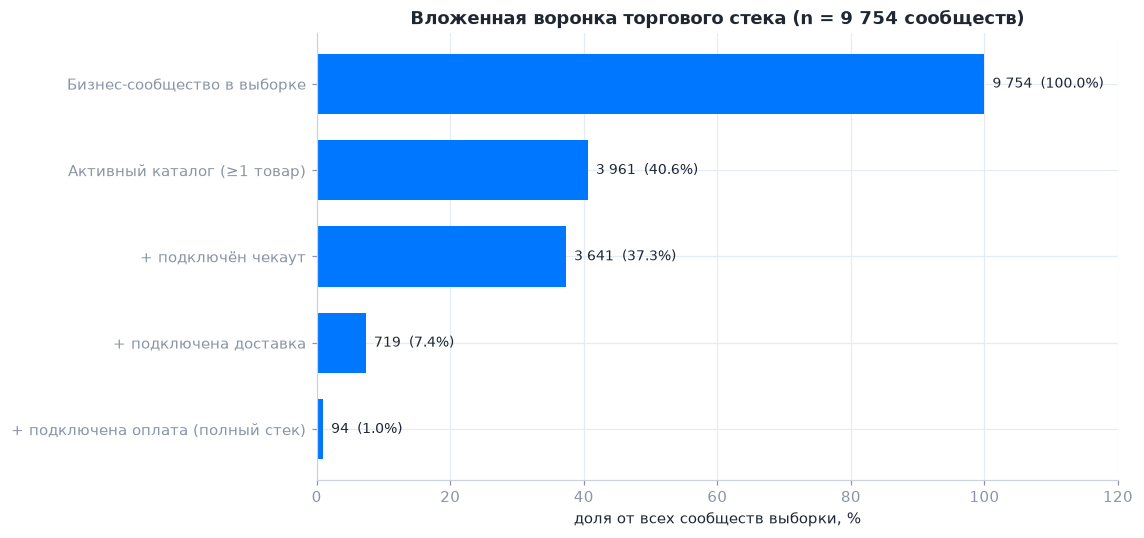

,step,n,share_of_all,step_conv
0,Бизнес-сообщество в выборке,9754,100.00,NaN
1,Активный каталог (≥1 товар),3961,40.61,40.6
2,+ подключён чекаут,3641,37.33,91.9
3,+ подключена доставка,719,7.37,19.7
4,+ подключена оплата (полный стек),94,0.96,13.1


In [2]:
funnel = an.activation_funnel(b)
data.save_table(funnel, "01_activation_funnel")
viz.activation_funnel_plot(funnel)
funnel.assign(share_of_all=lambda x: (x.share_of_all * 100).round(2),
              step_conv=lambda x: (x.step_conv * 100).round(1))

**Читаем воронку:**
* каталог есть у **40,6%** сообществ — это вход в товарную коммерцию;
* из имеющих каталог **91,9%** подключают чекаут → сам чекаут **не является барьером**;
* дальше обрыв: доставка только у **19,7%** имеющих чекаут, оплата — у **13,1%** имеющих доставку;
* полный стек (каталог+чекаут+доставка+оплата) — **94 сообщества, меньше 1% выборки**.

Гипотеза для стратегии: барьер не в «кнопке чекаута», а в **логистике и платежах**,
то есть в исполнении заказа, а не в его оформлении.

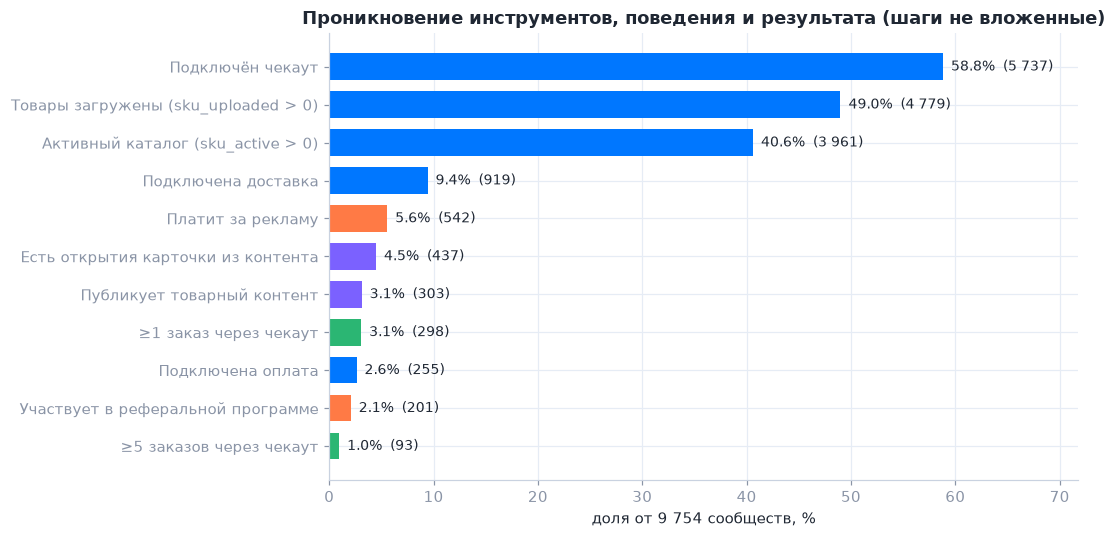

,indicator,n,group,share_of_all
0,Товары загружены (sku_uploaded > 0),4779,инструмент,49.00
1,Активный каталог (sku_active > 0),3961,инструмент,40.61
2,Подключён чекаут,5737,инструмент,58.82
3,Подключена доставка,919,инструмент,9.42
4,Подключена оплата,255,инструмент,2.61
5,Публикует товарный контент,303,поведение,3.11
6,Есть открытия карточки из контента,437,поведение,4.48
7,Платит за рекламу,542,монетизация,5.56
8,Участвует в реферальной программе,201,монетизация,2.06
9,≥1 заказ через чекаут,298,результат,3.06


In [3]:
pen = an.tool_penetration(b)
data.save_table(pen, "01_tool_penetration")
fig, ax = plt.subplots(figsize=(10, 5))
colors = {"инструмент": VK, "поведение": "#7B61FF", "монетизация": PARTNER, "результат": GOOD}
order = pen.sort_values("share_of_all")
ax.barh(order.indicator, order.share_of_all * 100,
        color=[colors[g] for g in order.group], height=0.7)
for i, (v, n) in enumerate(zip(order.share_of_all * 100, order.n)):
    ax.text(v, i, f"  {v:.1f}%  ({n:,})".replace(",", " "), va="center", fontsize=9)
ax.set_xlabel("доля от 9 754 сообществ, %")
ax.set_title("Проникновение инструментов, поведения и результата (шаги не вложенные)")
ax.margins(x=0.22)
fig.tight_layout(); viz.save(fig, "01_penetration")
pen.assign(share_of_all=lambda x: (x.share_of_all * 100).round(2))

## 2. Ключевой разрыв: «подключил → продал»

Это самая важная цифра всего анализа бизнесов.

In [4]:
chk = b[b.checkout == 1]
sellers = b[b.orders > 0]
gap = pd.DataFrame([
    ["Подключили чекаут", len(chk)],
    ["Из них сделали ≥1 заказ через чекаут", int(chk.has_order.sum())],
    ["Из них сделали ≥5 заказов", int((chk.orders >= 5).sum())],
    ["Подключили доставку", int((b.delivery == 1).sum())],
    ["Подключили оплату", int((b.payment == 1).sum())],
], columns=["шаг", "сообществ"])
gap["доля_от_чекаута"] = gap.сообществ / len(chk)
print(f"Чекаут подключён: {len(chk):,} сообществ")
print(f"Продают через него: {int(chk.has_order.sum()):,} ({chk.has_order.mean():.2%})")
print(f"«Спящих» (чекаут есть, заказов нет): {len(chk)-int(chk.has_order.sum()):,}")
data.save_table(gap, "01_activation_gap")
gap

Чекаут подключён: 5,737 сообществ
Продают через него: 284 (4.95%)
«Спящих» (чекаут есть, заказов нет): 5,453


,шаг,сообществ,доля_от_чекаута
0,Подключили чекаут,5737,1.000000
1,Из них сделали ≥1 заказ через чекаут,284,0.049503
2,Из них сделали ≥5 заказов,90,0.015688
3,Подключили доставку,919,0.160188
4,Подключили оплату,255,0.044448


> **Инсайт для слайда «Выявление проблематики».**
> Инструменты подключены массово, но **94,8% подключивших чекаут не сделали ни одного заказа**.
> Значит цель кейса «увеличить число бизнесов, продающих через ВКонтакте» решается
> **не привлечением новых сообществ, а активацией уже подключённых**.
> Это дешевле, быстрее и измеримо.

## 3. Сценарные сегменты

Сегментируем по **фактическому стеку** (что реально подключено), а не по типу бизнеса,
потому что тип «товарное» ничего не говорит о готовности продавать внутри VK.

In [5]:
prof = an.segment_profile(b)
data.save_table(prof, "01_segment_profile")
show = prof[["segment", "n", "share_of_all", "subs_median", "sku_median", "prod_content_share",
             "sellers", "sell_rate", "orders_per_biz", "gmv_per_seller", "ad_spend"]].copy()
show["share_of_all"] = (show.share_of_all * 100).round(1)
show["prod_content_share"] = (show.prod_content_share * 100).round(1)
show["sell_rate"] = (show.sell_rate * 100).round(2)
show.columns = ["сегмент", "n", "% выборки", "медиана подписчиков", "медиана SKU",
                "% с товарным контентом", "продающих", "% продающих", "заказов/бизнес",
                "GMV на продавца, ₽", "реклама, ₽"]
show

,сегмент,n,% выборки,медиана подписчиков,медиана SKU,% с товарным контентом,продающих,% продающих,заказов/бизнес,"GMV на продавца, ₽","реклама, ₽"
0,S0. Услуги без каталога,1626,16.7,350.0,0.0,0.6,0,0.00,0.000000,NaN,8243559
1,S1. Контент/переписка без товаров,2071,21.2,490.0,0.0,1.0,7,0.34,0.006277,13131.428571,14712000
2,S2. Чекаут без каталога (аномалия),2096,21.5,280.0,0.0,1.3,6,0.29,0.003340,2673.333333,9587413
3,S3. Витрина без чекаута,320,3.3,1300.0,19.5,14.1,7,2.19,0.100000,51682.857143,8051652
4,S4. Каталог + чекаут,2922,30.0,665.0,9.0,3.7,155,5.30,0.623888,27318.316129,43224500
5,S5. Каталог + чекаут + доставка,625,6.4,1000.0,39.0,12.5,107,17.12,2.137600,41309.420561,8070590
6,S6. Полный стек (+оплата),94,1.0,1250.0,59.0,16.0,16,17.02,2.840426,53052.500000,473700


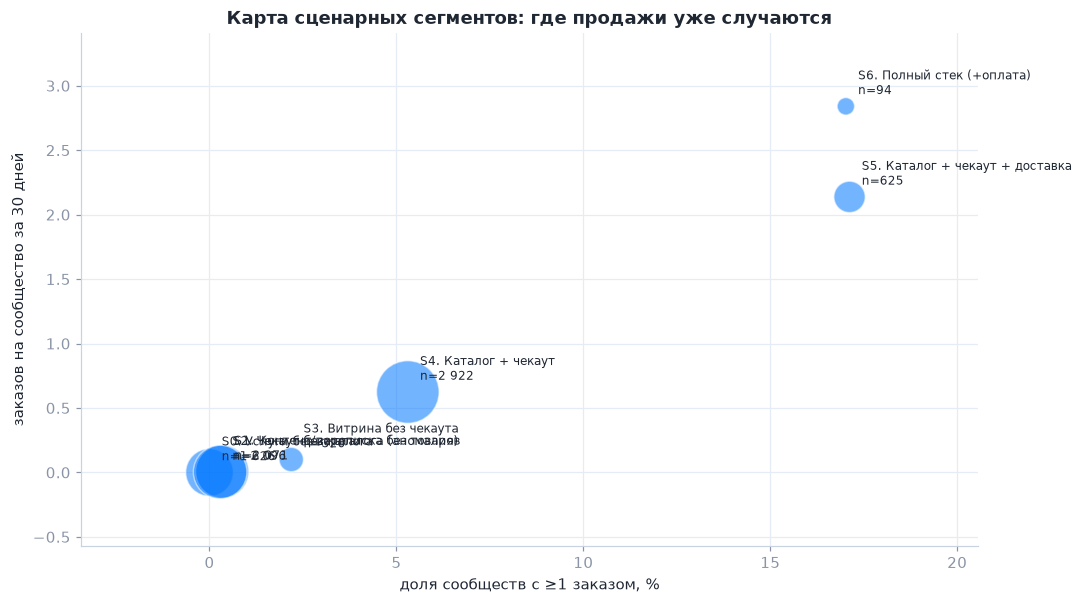

WindowsPath('C:/Users/Степан/Desktop/workspace/outputs/figures/segments_map.png')

In [6]:
viz.scatter_segment(prof)

**Как читать карту:** правее — чаще случается первая продажа, выше — больше заказов на сообщество,
размер пузыря — размер сегмента.

* **S4 «Каталог + чекаут»** — самый большой *товарный* сегмент (2 922), но продают лишь 5,3%.
  Это основной «спящий» пул.
* **S5 «+ доставка»** и **S6 «полный стек»** — продают в 3,2 раза чаще (≈17%), но это всего 719 сообществ.
* **S2 «Чекаут без каталога»** (2 096) — аномалия данных: инструмент есть, продавать нечего.
* **S0/S1** (услуги и контент без товаров, 3 697) — вне фокуса кейса (кейс просит сосредоточиться на товарах).

### 3.1. Проверка сопоставимости: а не потому ли S5 продаёт чаще, что он просто крупнее?

Требование кейса: *«сначала проверь, насколько группы сопоставимы»*.

In [7]:
combo = an.tool_combo_profile(b, only_catalog=True)
data.save_table(combo, "01_tool_combos")
combo_show = combo[combo.n >= 20].copy()
combo_show["sell_rate"] = (combo_show.sell_rate * 100).round(2)
combo_show["stack"] = combo_show.apply(
    lambda r: f"чекаут={int(r.checkout)}, доставка={int(r.delivery)}, оплата={int(r.payment)}", axis=1)
combo_show[["stack", "n", "subs_median", "sku_median", "views_median", "sellers", "sell_rate", "orders_per_biz"]]

,stack,n,subs_median,sku_median,views_median,sellers,sell_rate,orders_per_biz
0,"чекаут=0, доставка=0, оплата=0",227,1200.0,13.0,2000.0,4,1.76,0.096916
2,"чекаут=0, доставка=1, оплата=0",80,1850.0,70.0,4800.0,1,1.25,0.012500
4,"чекаут=1, доставка=0, оплата=0",2816,640.0,9.0,1300.0,145,5.15,0.636009
5,"чекаут=1, доставка=0, оплата=1",106,1750.0,15.5,2350.0,10,9.43,0.301887
6,"чекаут=1, доставка=1, оплата=0",625,1000.0,39.0,2800.0,107,17.12,2.137600
7,"чекаут=1, доставка=1, оплата=1",94,1250.0,59.0,1750.0,16,17.02,2.840426


**Важно:** сообщества с доставкой имеют медианный каталог **39 SKU против 9** у сообществ без доставки,
и медиану подписчиков 1 000 против 640. Группы **несопоставимы по размеру ассортимента**.
Поэтому «наивный» эффект доставки ×3,2 нельзя выносить на слайд как эффект инструмента —
корректную оценку с сопоставлением (PSM) делаем в ноутбуке 02.

## 4. Кто продаёт: размер, тематика, ассортимент

Продажи крайне концентрированы — это меняет логику приоритизации.

In [8]:
size = b.groupby("size_band", observed=True).agg(
    n=("biz_id", "size"), catalog_share=("has_catalog", "mean"), checkout=("checkout", "mean"),
    delivery=("delivery", "mean"), sellers=("has_order", "sum"), orders=("orders", "sum"),
    gmv=("gmv", "sum"), ad_spend=("ad_spend", "sum"))
size["sell_rate"] = size.sellers / size.n
size["orders_per_biz"] = size.orders / size.n
data.save_table(size.reset_index(), "01_size_bands")
size.assign(catalog_share=lambda x: (x.catalog_share*100).round(1),
            checkout=lambda x: (x.checkout*100).round(1),
            delivery=lambda x: (x.delivery*100).round(1),
            sell_rate=lambda x: (x.sell_rate*100).round(2))

,n,catalog_share,checkout,delivery,sellers,orders,gmv,ad_spend,sell_rate,orders_per_biz
size_band,,,,,,,,,,
0–100,2057,28.0,60.5,5.0,19,29,100680,1078183,0.92,0.014098
100–1k,4375,38.7,56.0,8.3,54,136,742820,7081232,1.23,0.031086
1k–10k,2904,50.1,62.3,12.9,158,1548,4747473,32452799,5.44,0.533058
10k–50k,361,57.1,56.8,19.1,55,1465,3006266,42072400,15.24,4.058172
50k+,57,52.6,52.6,19.3,12,300,1375788,9678800,21.05,5.263158


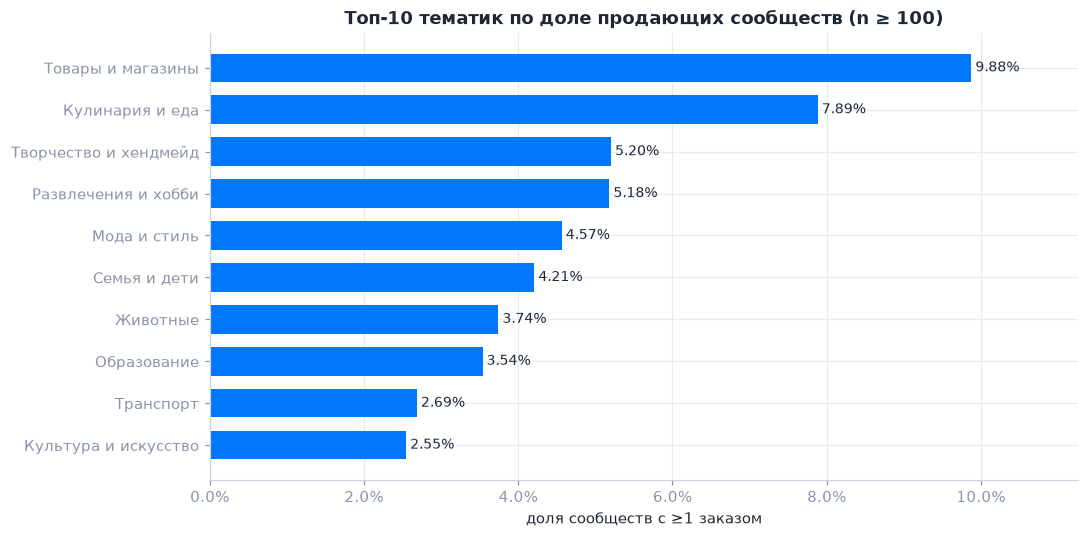

,n,catalog,checkout,delivery,sellers,orders,gmv,ad_spend,subs_median,sell_rate,aov
theme,,,,,,,,,,,
Товары и магазины,405,64.9,0.800000,0.204938,40,338,1587270,5782804,350.0,9.88,4696.065089
Кулинария и еда,837,56.2,0.667861,0.143369,66,1187,2405730,4282200,830.0,7.89,2026.731255
Творчество и хендмейд,538,54.5,0.671004,0.178439,28,339,291680,5036790,380.0,5.20,860.412979
Развлечения и хобби,328,51.8,0.685976,0.137195,17,55,203543,1839313,640.0,5.18,3700.781818
Мода и стиль,460,55.9,0.706522,0.158696,21,154,583861,22503453,860.0,4.57,3791.305195
Семья и дети,190,56.8,0.736842,0.163158,8,31,38460,582010,615.0,4.21,1240.645161
Животные,187,40.6,0.631016,0.080214,7,24,90360,500000,710.0,3.74,3765.000000
Образование,537,38.0,0.510242,0.059590,19,337,631710,11705913,560.0,3.54,1874.510386
Транспорт,521,39.5,0.568138,0.092131,14,176,1229470,5215946,620.0,2.69,6985.625000


In [9]:
theme = b.groupby("theme").agg(
    n=("biz_id", "size"), catalog=("has_catalog", "mean"), checkout=("checkout", "mean"),
    delivery=("delivery", "mean"), sellers=("has_order", "sum"), orders=("orders", "sum"),
    gmv=("gmv", "sum"), ad_spend=("ad_spend", "sum"), subs_median=("subs", "median"))
theme["sell_rate"] = theme.sellers / theme.n
theme["aov"] = theme.gmv / theme.orders.replace(0, np.nan)
theme = theme[theme.n >= 100].sort_values("sell_rate", ascending=False)
data.save_table(theme.reset_index(), "01_themes")
viz.hbar(theme.reset_index().head(10), "theme", "sell_rate",
         "Топ-10 тематик по доле продающих сообществ (n ≥ 100)", "01_themes_sell_rate",
         color=VK, fmt="pct", xlabel="доля сообществ с ≥1 заказом")
theme.head(10).assign(sell_rate=lambda x: (x.sell_rate*100).round(2),
                      catalog=lambda x: (x.catalog*100).round(1))

In [10]:
gini_orders = an.gini(b.orders.values)
top10 = b.orders.nlargest(10).sum() / b.orders.sum()
top1pct = b.orders.nlargest(int(N * 0.01)).sum() / b.orders.sum()
print(f"Джини по заказам: {gini_orders:.3f}")
print(f"Топ-10 сообществ дают {top10:.1%} всех заказов выборки")
print(f"Топ-1% сообществ ({int(N*0.01)}) дают {top1pct:.1%} заказов")
print(f"Медиана заказов среди продающих: {b.loc[b.orders>0,'orders'].median():.0f}")

Джини по заказам: 0.994
Топ-10 сообществ дают 54.0% всех заказов выборки
Топ-1% сообществ (97) дают 90.9% заказов
Медиана заказов среди продающих: 2


**Вывод:** 1% сообществ даёт 91% заказов. Стратегия «поднять всех» не работает —
нужны **разные траектории**: (а) массовая активация первой продажи для длинного хвоста,
(б) рост объёма для узкой группы уже продающих.

## 5. Реклама: кто платит и получает ли результат

Это прямой ответ на реплику Дмитрия в кейсе: *«сейчас мы зарабатываем прежде всего на рекламе…
хотим, чтобы предприниматель получал результат и был готов платить»*.

In [11]:
ad_band = pd.cut(b.ad_spend, [-1, 0, 10_000, 100_000, 1_000_000, 1e12],
                 labels=["0 ₽", "1–10 тыс.", "10–100 тыс.", "100 тыс.–1 млн", ">1 млн"])
ad_band.name = "ad_band"  # иначе имя индекса совпадёт с агрегатом ad_spend при reset_index
ads = b.groupby(ad_band, observed=True).agg(
    n=("biz_id", "size"), sellers=("has_order", "sum"), orders=("orders", "sum"),
    gmv=("gmv", "sum"), ad_spend=("ad_spend", "sum"), subs_median=("subs", "median"),
    checkout=("checkout", "mean"), delivery=("delivery", "mean"))
ads["sell_rate"] = ads.sellers / ads.n
ads["gmv_per_ad_rub"] = ads.gmv / ads.ad_spend.replace(0, np.nan)
data.save_table(ads.reset_index(), "01_ad_bands")
ads.assign(sell_rate=lambda x: (x.sell_rate*100).round(2),
           checkout=lambda x: (x.checkout*100).round(1),
           delivery=lambda x: (x.delivery*100).round(1))

,n,sellers,orders,gmv,ad_spend,subs_median,checkout,delivery,sell_rate,gmv_per_ad_rub
ad_band,,,,,,,,,,
0 ₽,9212,257,3173,7018324,0,460.0,58.7,8.9,2.79,NaN
1–10 тыс.,109,6,14,111300,506414,610.0,60.6,14.7,5.50,0.219781
10–100 тыс.,270,18,64,889330,11387000,1950.0,63.3,19.6,6.67,0.078100
100 тыс.–1 млн,153,15,204,1892563,44170000,4700.0,58.8,17.6,9.80,0.042847
>1 млн,10,2,23,61510,36300000,33500.0,70.0,20.0,20.00,0.001694


In [12]:
payers = b[b.ad_spend > 0]
no_order_payers = payers[payers.orders == 0]
print(f"Плательщиков рекламы: {len(payers)} ({len(payers)/N:.2%} выборки)")
print(f"Из них без единого заказа через чекаут: {len(no_order_payers)} ({len(no_order_payers)/len(payers):.1%})")
print(f"Их бюджет: {no_order_payers.ad_spend.sum():,.0f} ₽ ({no_order_payers.ad_spend.sum()/payers.ad_spend.sum():.1%} всех трат)")
ok = payers[payers.gmv > 0]
print(f"\nGMV через чекаут / траты на рекламу (плательщики с GMV>0, n={len(ok)}): {ok.gmv.sum()/ok.ad_spend.sum():.3f}")
print(f"Медианный ROAS по сообществам: {ok.roas.median():.3f}")
print("\n!!! Это НИЖНЯЯ оценка: продажи через сообщения и внешний сайт в данных не видны (см. ноутбук 00).")

Плательщиков рекламы: 542 (5.56% выборки)
Из них без единого заказа через чекаут: 501 (92.4%)
Их бюджет: 80,897,762 ₽ (87.6% всех трат)

GMV через чекаут / траты на рекламу (плательщики с GMV>0, n=39): 0.259
Медианный ROAS по сообществам: 0.199

!!! Это НИЖНЯЯ оценка: продажи через сообщения и внешний сайт в данных не видны (см. ноутбук 00).


> **Инсайт для слайда «Проблематика» и для монетизации.**
> 92% рекламодателей выборки не получают ни одного *измеримого* заказа, и на них уходит 88% бюджета.
> Даже если часть продаж происходит в сообщениях, **бизнес не видит связи «реклама → продажа»**,
> а значит не будет наращивать бюджет. Реклама без замкнутой сделки — это тупик монетизации.

Продуктовый вывод: сначала **«доделать сделку»** (чекаут → доставка → оплата → атрибуция),
и только потом продавать трафик.

## 6. Приоритизация целевых сегментов

Скоринг = **потенциал** (сколько заказов может дать) × **готовность** (насколько близко к сделке)
× **доступность рычага** (есть ли у нас инструмент, чтобы это изменить).
Все компоненты считаем из данных, веса — экспертное допущение (прозрачно указано).

In [13]:
lev = {
    # segment: (рычаг, доля сегмента, достижимая sell_rate, источник оценки)
    "S4. Каталог + чекаут": ("Подключить доставку/оплату «в один клик» + шаблоны логистики", 0.35, None,
                             "уровень S5 с поправкой на self-selection (PSM, ноутбук 02)"),
    "S3. Витрина без чекаута": ("Включить чекаут по умолчанию для сообществ с каталогом", 0.50, None,
                                "переход на уровень S4"),
    "S2. Чекаут без каталога (аномалия)": ("Импорт каталога (Ozon/CSV/фото→карточка) + разбор аномалии", 0.25, None,
                                           "переход на уровень S4 после наполнения каталога"),
    "S5. Каталог + чекаут + доставка": ("Шопсы/контент + реклама на карточку, оплата внутри VK", 0.60, None,
                                        "рост объёма у уже продающих"),
    "S6. Полный стек (+оплата)": ("Масштабирование: реферальная программа, ретаргетинг, подписка", 0.80, None,
                                  "рост объёма"),
}
base = prof.set_index("segment")
s5_rate = base.loc["S5. Каталог + чекаут + доставка", "sell_rate"]
s4_rate = base.loc["S4. Каталог + чекаут", "sell_rate"]
rows = []
for seg, (lever, reach, _, src) in lev.items():
    r = base.loc[seg]
    target_rate = {"S4. Каталог + чекаут": s4_rate + 0.5 * (s5_rate - s4_rate),
                   "S3. Витрина без чекаута": s4_rate,
                   "S2. Чекаут без каталога (аномалия)": s4_rate,
                   "S5. Каталог + чекаут + доставка": r.sell_rate,
                   "S6. Полный стек (+оплата)": r.sell_rate}[seg]
    new_sellers = max(0.0, (target_rate - r.sell_rate)) * r.n * reach
    rows.append({"сегмент": seg, "n": int(r.n), "текущая доля продающих": r.sell_rate,
                 "рычаг": lever, "охват рычага": reach,
                 "целевая доля продающих": target_rate,
                 "новых продающих бизнесов": new_sellers,
                 "заказов/бизнес сейчас": r.orders_per_biz, "основание оценки": src})
prior = pd.DataFrame(rows).sort_values("новых продающих бизнесов", ascending=False)
data.save_table(prior, "01_target_priorities")
prior.assign(**{"текущая доля продающих": lambda x: (x["текущая доля продающих"]*100).round(2),
                "целевая доля продающих": lambda x: (x["целевая доля продающих"]*100).round(2),
                "охват рычага": lambda x: (x["охват рычага"]*100).round(0)})

,сегмент,n,текущая доля продающих,рычаг,охват рычага,целевая доля продающих,новых продающих бизнесов,заказов/бизнес сейчас,основание оценки
0,S4. Каталог + чекаут,2922,5.30,Подключить доставку/оплату «в один клик» + шаб...,35.0,11.21,60.418120,0.623888,"уровень S5 с поправкой на self-selection (PSM,..."
2,S2. Чекаут без каталога (аномалия),2096,0.29,Импорт каталога (Ozon/CSV/фото→карточка) + раз...,25.0,5.30,26.296030,0.003340,переход на уровень S4 после наполнения каталога
1,S3. Витрина без чекаута,320,2.19,Включить чекаут по умолчанию для сообществ с к...,50.0,5.30,4.987337,0.100000,переход на уровень S4
3,S5. Каталог + чекаут + доставка,625,17.12,"Шопсы/контент + реклама на карточку, оплата вн...",60.0,17.12,0.000000,2.137600,рост объёма у уже продающих
4,S6. Полный стек (+оплата),94,17.02,"Масштабирование: реферальная программа, ретарг...",80.0,17.02,0.000000,2.840426,рост объёма


In [14]:
print(f"Суммарный потенциал активации в выборке: +{prior['новых продающих бизнесов'].sum():,.0f} продающих сообществ")
print(f"Это +{prior['новых продающих бизнесов'].sum()/b.has_order.sum():.0%} к текущему числу продающих ({int(b.has_order.sum())})")
print("\nВажно: охват рычага — экспертное допущение, чувствительность считаем в ноутбуке 04.")

Суммарный потенциал активации в выборке: +92 продающих сообществ
Это +31% к текущему числу продающих (298)

Важно: охват рычага — экспертное допущение, чувствительность считаем в ноутбуке 04.


## 7. Портреты целевых сегментов (для слайда «целевые бизнесы и их боли»)

Собираем из данных то, что можно утверждать, и формулируем боли как гипотезы для проверки.

In [15]:
portrait = pd.DataFrame([
    ["S4 «Спящий магазин»", 2922, "каталог ~9 SKU, 665 подписчиков, чекаут есть, доставки нет",
     "хочет заказы без своего сайта и логистики",
     "не может исполнить заказ: доставка/оплата не подключены; карточка не ведёт к сделке",
     "доставка «из коробки» + оплата + автогенерация карточек; обучение в 3 шага"],
    ["S3 «Витрина-каталог»", 320, "каталог ~20 SKU, 1 300 подписчиков, чекаута нет",
     "показывать ассортимент и получать заявки",
     "сделка уходит в сообщения, потеря конверсии и учёта",
     "чекаут по умолчанию + шаблоны ответов с карточкой"],
    ["S2 «Пустой чекаут»", 2096, "чекаут подключён, каталог пуст, 280 подписчиков",
     "попробовать продажи без затрат",
     "нет наполненного каталога (барьер загрузки товаров)",
     "импорт каталога из маркетплейса/CSV, карточка из фото"],
    ["S5/S6 «Работающий продавец»", 719, "39–59 SKU, 1 000–1 250 подписчиков, доставка есть",
     "масштабировать заказы и повторные покупки",
     "мало нового трафика; товарный контент не даёт переходов в карточку",
     "шопсы + реклама на карточку + реферальная программа + оплата внутри VK"],
], columns=["сегмент", "n", "профиль из данных", "цель бизнеса", "барьер (гипотеза)", "что даём"])
data.save_table(portrait, "01_target_portraits")
portrait

,сегмент,n,профиль из данных,цель бизнеса,барьер (гипотеза),что даём
0,S4 «Спящий магазин»,2922,"каталог ~9 SKU, 665 подписчиков, чекаут есть, ...",хочет заказы без своего сайта и логистики,не может исполнить заказ: доставка/оплата не п...,доставка «из коробки» + оплата + автогенерация...
1,S3 «Витрина-каталог»,320,"каталог ~20 SKU, 1 300 подписчиков, чекаута нет",показывать ассортимент и получать заявки,"сделка уходит в сообщения, потеря конверсии и ...",чекаут по умолчанию + шаблоны ответов с карточкой
2,S2 «Пустой чекаут»,2096,"чекаут подключён, каталог пуст, 280 подписчиков",попробовать продажи без затрат,нет наполненного каталога (барьер загрузки тов...,"импорт каталога из маркетплейса/CSV, карточка ..."
3,S5/S6 «Работающий продавец»,719,"39–59 SKU, 1 000–1 250 подписчиков, доставка есть",масштабировать заказы и повторные покупки,мало нового трафика; товарный контент не даёт ...,шопсы + реклама на карточку + реферальная прог...


In [16]:
data.save_key_numbers({
    "catalog_share": float(b.has_catalog.mean()),
    "checkout_share": float(b.checkout.mean()),
    "sellers_share": float(b.has_order.mean()),
    "checkout_to_seller_rate": float(b.loc[b.checkout == 1, "has_order"].mean()),
    "sleeping_checkout": int((b.checkout == 1).sum() - (b[b.checkout == 1].has_order).sum()),
    "s4_n": int(base.loc["S4. Каталог + чекаут", "n"]),
    "s4_sell_rate": float(s4_rate),
    "s5_sell_rate": float(s5_rate),
    "gini_orders": gini_orders,
    "top1pct_orders_share": float(top1pct),
    "ad_payers": int(len(payers)),
    "ad_payers_without_orders": int(len(no_order_payers)),
    "ad_budget_without_orders_share": float(no_order_payers.ad_spend.sum() / payers.ad_spend.sum()),
    "roas_lower_bound": float(ok.gmv.sum() / ok.ad_spend.sum()),
    "activation_potential_new_sellers": float(prior["новых продающих бизнесов"].sum()),
}, "01_segments")
b.to_csv(data.TABLES / "01_businesses_segmented.csv", index=False, encoding="utf-8-sig")
print("Сохранено: outputs/tables/01_*.csv")

Сохранено: outputs/tables/01_*.csv


## Итоги ноутбука 01

1. **Барьер — не чекаут, а исполнение заказа.** Чекаут подключают 92% сообществ с каталогом,
   доставку — 20% из них, оплату — 13% из имеющих доставку. Полный стек — <1% выборки.
2. **94,8% подключивших чекаут не продают.** Главный резерв роста — активация, а не привлечение.
3. **Сегменты несопоставимы по размеру каталога** (39 vs 9 SKU) → наивные сравнения завышают эффект инструментов.
4. **1% сообществ = 91% заказов** → нужны две разные траектории: «первая продажа» и «масштабирование».
5. **92% рекламодателей без измеримых заказов, 88% бюджета** → реклама без замкнутой сделки не удержит бизнес.
6. Приоритет №1 — **S4 «Спящий магазин»** (2 922 сообщества): ближе всего к сделке и самый большой товарный пул.

**Дальше:** ноутбук 02 — контент и корректная оценка драйверов продаж.